---
# **NYC Yellow Taxi**
## **Regresión y comparación con PySpark y MLlib**
---

El objetivo de este notebook es estimar la tarifa del taxímetro con la distancia y la duración de un recorrido conocido. También revisamos si la hora y el día de la semana aportan información. Procesamos el CSV de enero de 2015, de 1.99 GB, con PySpark y comparamos regresión lineal y GBT. La ejecución recibida utiliza Spark 4.0.5.

La distancia y la duración reales se conocen al finalizar el viaje. Por eso estimamos la tarifa de un recorrido terminado, no una cotización antes de salir. La tarifa no incluye propinas, peajes ni otros cargos del total pagado.

### **1. Entorno y Configuración**

Trabajamos en Google Colab con CPU y PySpark disponible. Si faltan dependencias, ejecutamos `%pip install pyspark==4.0.5 kagglehub pandas matplotlib` en una celda antes de importar y reiniciamos el entorno si es necesario.

Importamos las librerías que vamos a utilizar durante el proceso.

In [1]:
from pathlib import Path
from time import perf_counter
import shutil

import kagglehub
import pandas as pd
import matplotlib.pyplot as plt

from pyspark import StorageLevel
from pyspark.sql import SparkSession, functions as F
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression, GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator

Definimos la ruta del archivo, el tamaño máximo de la muestra para Tableau y los parámetros de GBT.

In [2]:
SEED = 42
CSV_MANUAL = None  # Ruta alternativa al CSV completo.
DATASET = "elemento/nyc-yellow-taxi-trip-data"
ARCHIVO = "yellow_tripdata_2015-01.csv"
MAX_PREDICCIONES = 20_000
SALIDAS = (
    Path("/content/tableau_taxi") if Path("/content").exists() else Path.cwd() / "tableau_taxi"
)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
ITERACIONES_GBT = 20
PROFUNDIDAD_GBT = 3

Inicializamos Spark para trabajar con el CSV completo y solicitamos un límite de 4 GB para su proceso Java principal. Este valor no representa toda la memoria utilizada por Colab.

In [3]:
spark = (
    SparkSession.builder.appName("NYC_Taxi_Regresion")
    .config("spark.driver.memory", "4g")
    .getOrCreate()
)

print("Spark:", spark.version)

Spark: 4.0.5


### **2. Carga del Dataset**

Utilizamos el CSV de enero de 2015 de [Kaggle](https://www.kaggle.com/datasets/elemento/nyc-yellow-taxi-trip-data), de aproximadamente 1.99 GB.


Descargamos únicamente el archivo necesario y verificamos que cumpla el requisito mínimo de 1 GB.

In [4]:
if CSV_MANUAL:
    csv_path = Path(CSV_MANUAL)
else:
    descarga = Path(kagglehub.dataset_download(DATASET, path=ARCHIVO))
    csv_path = descarga if descarga.is_file() else descarga / ARCHIVO

if not csv_path.is_file():
    raise FileNotFoundError(f"No se encontró el CSV: {csv_path}")
bytes_csv = csv_path.stat().st_size
if bytes_csv < 1_000_000_000:
    raise ValueError("El CSV debe cumplir el mínimo de 1 GB de la actividad.")
print(f"{csv_path.name}: {bytes_csv / 1e9:.2f} GB")

yellow_tripdata_2015-01.csv: 1.99 GB


Leemos el CSV y conservamos únicamente los campos necesarios para nuestro modelo y el tablero.

In [5]:
raw = spark.read.option("header", True).option("mode", "FAILFAST").csv(str(csv_path))
raw = raw.toDF(*[nombre.strip().lower() for nombre in raw.columns])

columnas = {
    "tpep_pickup_datetime": "inicio",
    "tpep_dropoff_datetime": "fin",
    "trip_distance": "distancia_mi",
    "fare_amount": "tarifa",
    "ratecodeid": "tipo_tarifa",
    "payment_type": "tipo_pago",
    "pickup_latitude": "latitud",
    "pickup_longitude": "longitud",
}

datos = raw.select([F.col(origen).alias(destino) for origen, destino in columnas.items()])

Revisamos cinco registros para comprobar que la carga y los nombres de las columnas sean correctos.

In [6]:
datos.show(5, truncate=False)

+-------------------+-------------------+------------+------+-----------+---------+------------------+-------------------+
|inicio             |fin                |distancia_mi|tarifa|tipo_tarifa|tipo_pago|latitud           |longitud           |
+-------------------+-------------------+------------+------+-----------+---------+------------------+-------------------+
|2015-01-15 19:05:39|2015-01-15 19:23:42|1.59        |12    |1          |1        |40.750110626220703|-73.993896484375   |
|2015-01-10 20:33:38|2015-01-10 20:53:28|3.30        |14.5  |1          |1        |40.7242431640625  |-74.00164794921875 |
|2015-01-10 20:33:38|2015-01-10 20:43:41|1.80        |9.5   |1          |2        |40.802787780761719|-73.963340759277344|
|2015-01-10 20:33:39|2015-01-10 20:35:31|.50         |3.5   |1          |2        |40.713817596435547|-74.009086608886719|
|2015-01-10 20:33:39|2015-01-10 20:52:58|3.00        |15    |1          |2        |40.762428283691406|-73.971176147460938|
+---------------

### **3. Limpieza y Selección de Variables**

Conservamos viajes estándar de enero: 0.1–100 millas, 1–180 minutos y 2.5–300 USD, con recogida en el área delimitada. La variable objetivo es `tarifa`, tomada de `fare_amount`. No utilizamos `total_amount` como predictor porque incluye la tarifa y otros cargos.

Convertimos fechas y números, y calculamos la duración del recorrido en minutos.

In [7]:
viajes = datos.withColumn("inicio", F.to_timestamp("inicio", "yyyy-MM-dd HH:mm:ss")).withColumn(
    "fin", F.to_timestamp("fin", "yyyy-MM-dd HH:mm:ss")
)

for columna in ["distancia_mi", "tarifa", "latitud", "longitud"]:
    viajes = viajes.withColumn(columna, F.col(columna).cast("double"))

for columna in ["tipo_tarifa", "tipo_pago"]:
    viajes = viajes.withColumn(columna, F.col(columna).cast("int"))

viajes = viajes.withColumn(
    "duracion_min", (F.col("fin").cast("long") - F.col("inicio").cast("long")) / 60
)

Aplicamos los filtros para retirar registros incompletos o fuera del alcance.

In [8]:
validos = viajes.filter(
    (F.col("tipo_tarifa") == 1)
    & (F.col("inicio") >= F.lit("2015-01-01").cast("timestamp"))
    & (F.col("inicio") < F.lit("2015-02-01").cast("timestamp"))
    & F.col("distancia_mi").between(0.1, 100)
    & F.col("duracion_min").between(1, 180)
    & F.col("tarifa").between(2.5, 300)
    & F.col("latitud").between(40.4, 41.2)
    & F.col("longitud").between(-74.3, -73.5)
)

Definimos cómo obtener la hora y el día de la semana desde el inicio del viaje. Usamos lunes = 1 y domingo = 7, conservando la hora local.

In [9]:
def agregar_calendario(tabla):
    """Obtener el calendario desde la hora local de inicio."""
    return (
        tabla.withColumn("fecha", F.to_date("inicio"))
        .withColumn("hora", F.hour("inicio"))
        .withColumn("dia_semana", F.pmod(F.dayofweek("inicio") + 5, F.lit(7)) + 1)
    )

Quitamos repeticiones y preparamos la tabla que vamos a reutilizar. Evitamos los conteos intermedios para reducir lecturas del CSV.

In [10]:
limpios = (
    agregar_calendario(validos.dropDuplicates())
    .withColumn(
        "pago",
        F.when(F.col("tipo_pago") == 1, "Tarjeta")
        .when(F.col("tipo_pago") == 2, "Efectivo")
        .otherwise("Otro"),
    )
    .select(
        "inicio",
        "fin",
        "fecha",
        "hora",
        "dia_semana",
        "pago",
        "latitud",
        "longitud",
        "distancia_mi",
        "duracion_min",
        "tarifa",
    )
    .persist(StorageLevel.MEMORY_AND_DISK)
)
n_limpios = limpios.count()

Comprobamos el volumen que quedó disponible después de limpiar los datos.

In [11]:
print(pd.DataFrame({"CSV_GB": [bytes_csv / 1e9], "Viajes_limpios": [n_limpios]}).round(2).to_string(index=False))

 CSV_GB  Viajes_limpios
   1.99        12143647


Finalmente, conservamos **12,143,647 viajes** después de aplicar los filtros y retirar repeticiones. El CSV original tiene **1.99 GB**, por lo que cumple el requisito de tamaño. El análisis y el tablero describen los viajes que quedaron dentro de este alcance.

### **4. Análisis Exploratorio**

Revisamos los rangos de distancia, duración y tarifa antes de entrenar.

In [12]:
limpios.select("distancia_mi", "duracion_min", "tarifa").summary("min", "50%", "max").show()

+-------+------------+------------------+------+
|summary|distancia_mi|      duracion_min|tarifa|
+-------+------------+------------------+------+
|    min|         0.1|               1.0|   2.5|
|    50%|        1.64| 9.866666666666667|   9.0|
|    max|       100.0|179.96666666666667| 261.5|
+-------+------------+------------------+------+



La mitad de los viajes tuvo una distancia de hasta **1.64 millas**, una duración cercana a **9.87 minutos** y una tarifa de hasta **9 USD**. Predominan valores centrales moderados, aunque los máximos muestran recorridos más largos y caros.

Visualizamos las distribuciones de distancia, duración y tarifa con una muestra aleatoria de hasta 20,000 viajes, utilizada únicamente para graficar. Mostramos cada variable hasta su percentil 99 para distinguir los valores más frecuentes; este límite visual no modifica la limpieza ni los datos del modelo.

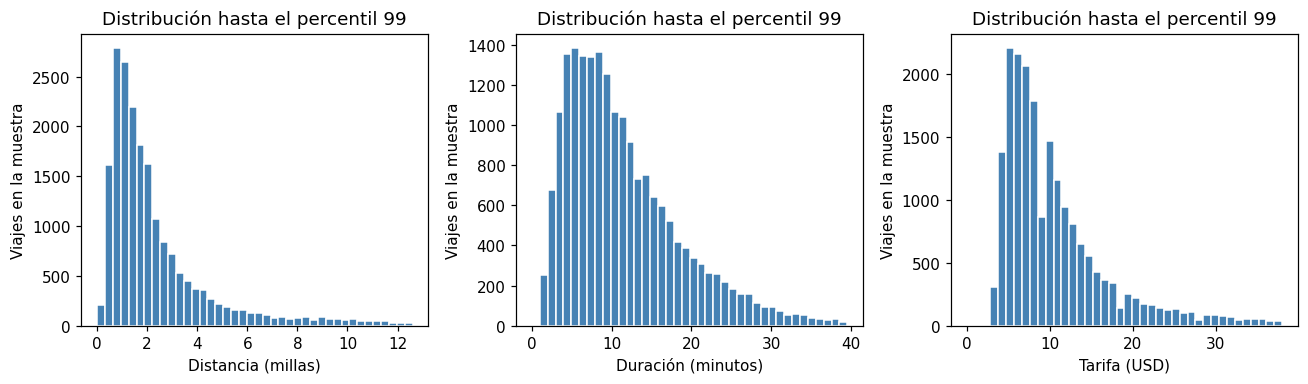

In [13]:
muestra_eda = (
    limpios.select("distancia_mi", "duracion_min", "tarifa")
    .sample(False, min(1.0, 20_000 / n_limpios), seed=SEED)
    .limit(20_000)
    .toPandas()
)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, columna, etiqueta in zip(
    axes,
    ["distancia_mi", "duracion_min", "tarifa"],
    ["Distancia (millas)", "Duración (minutos)", "Tarifa (USD)"],
):
    limite = muestra_eda[columna].quantile(0.99)
    ax.hist(muestra_eda[columna], bins=40, range=(0, limite), color="steelblue", edgecolor="white")
    ax.set(xlabel=etiqueta, ylabel="Viajes en la muestra", title="Distribución hasta el percentil 99")
plt.tight_layout()
plt.show()
plt.close(fig)

En la muestra de **19,868 viajes**, el percentil 99 fue **12.60 millas**, **39.55 minutos** y **38.00 USD**. Las distribuciones se concentran en viajes cortos y tarifas bajas, con una cola hacia valores mayores. Esta forma ayuda a entender por qué unos pocos errores grandes pueden elevar el RMSE.

Calculamos las correlaciones de Pearson con todos los viajes limpios y convertimos únicamente la matriz pequeña a pandas para graficarla. Revisamos la relación de distancia y duración con la tarifa y la relación entre ambas entradas. No tratamos la hora ni el día como escalas lineales: su posible aporte se explora con las gráficas de calendario y la comparación de modelos.

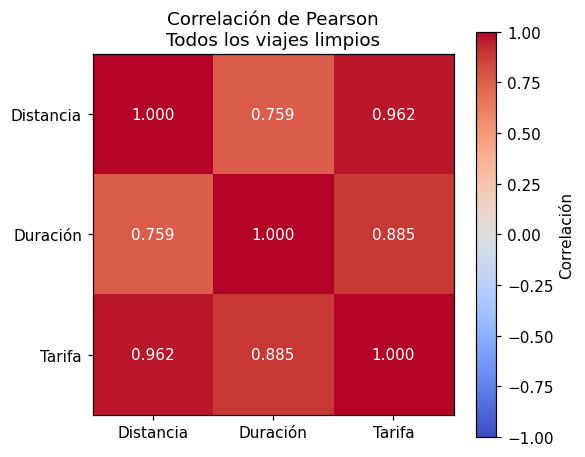

In [14]:
columnas_corr = ["distancia_mi", "duracion_min", "tarifa"]
pares_corr = [
    (columna, otra)
    for i, columna in enumerate(columnas_corr)
    for otra in columnas_corr[i + 1:]
]
valores_corr = limpios.agg(
    *[F.corr(columna, otra).alias(f"r_{i}") for i, (columna, otra) in enumerate(pares_corr)]
).first()
matriz_corr = pd.DataFrame(1.0, index=columnas_corr, columns=columnas_corr)
for i, (columna, otra) in enumerate(pares_corr):
    matriz_corr.loc[columna, otra] = valores_corr[f"r_{i}"]
    matriz_corr.loc[otra, columna] = valores_corr[f"r_{i}"]

fig, ax = plt.subplots(figsize=(5.4, 4.5))
imagen = ax.imshow(matriz_corr, cmap="coolwarm", vmin=-1, vmax=1)
etiquetas_corr = ["Distancia", "Duración", "Tarifa"]
ax.set_xticks(range(3), etiquetas_corr)
ax.set_yticks(range(3), etiquetas_corr)
for i in range(3):
    for j in range(3):
        valor = matriz_corr.iloc[i, j]
        ax.text(j, i, f"{valor:.3f}", ha="center", va="center", color="white" if abs(valor) > 0.6 else "black")
ax.set_title("Correlación de Pearson\nTodos los viajes limpios")
fig.colorbar(imagen, ax=ax, label="Correlación")
plt.tight_layout()
plt.show()
plt.close(fig)

La correlación de la tarifa con la distancia fue **0.962** y con la duración **0.885**. Estas relaciones positivas respaldan probar ambas entradas en la regresión base. La correlación entre distancia y duración fue **0.759**, por lo que comparten parte de su información. Estos valores no demuestran causalidad ni sustituyen la evaluación con validación y prueba.

Graficamos la tarifa frente a cada entrada con la misma muestra. El color representa la cantidad de viajes en cada zona y permite observar la forma de la relación sin superponer miles de puntos. Mostramos hasta el percentil 99 de cada eje, únicamente como ajuste visual.

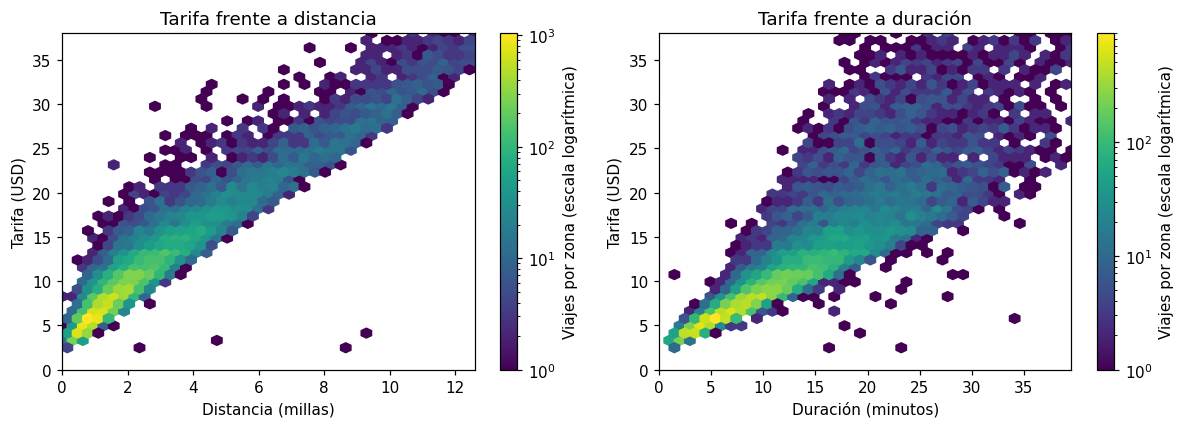

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, columna, etiqueta in zip(
    axes,
    ["distancia_mi", "duracion_min"],
    ["Distancia (millas)", "Duración (minutos)"],
):
    limite_x = muestra_eda[columna].quantile(0.99)
    limite_y = muestra_eda["tarifa"].quantile(0.99)
    imagen = ax.hexbin(
        muestra_eda[columna], muestra_eda["tarifa"],
        gridsize=40, mincnt=1, bins="log", cmap="viridis",
        extent=(0, limite_x, 0, limite_y),
    )
    ax.set(xlim=(0, limite_x), ylim=(0, limite_y), xlabel=etiqueta, ylabel="Tarifa (USD)", title=f"Tarifa frente a {etiqueta.split(' (')[0].lower()}")
    fig.colorbar(imagen, ax=ax, label="Viajes por zona (escala logarítmica)")
plt.tight_layout()
plt.show()
plt.close(fig)

La tarifa tiende a aumentar con la distancia y la duración, aunque observamos dispersión y viajes con distintas tarifas para valores similares de cada entrada. Esta tendencia respalda la regresión lineal como referencia y permite considerar GBT para explorar relaciones más flexibles. La selección depende del error de validación.

Resumimos la tarifa media por hora y día para explorar diferencias de calendario. Estas diferencias no demuestran un efecto causal y también pueden reflejar cambios en la distancia o duración de los viajes.

In [16]:
por_hora = (
    limpios.groupBy("hora")
    .agg(F.avg("tarifa").alias("tarifa_media"))
    .orderBy("hora")
    .toPandas()
)
por_dia = (
    limpios.groupBy("dia_semana")
    .agg(F.avg("tarifa").alias("tarifa_media"))
    .orderBy("dia_semana")
    .toPandas()
)

Visualizamos los resúmenes calculados con todos los viajes limpios. Solo convertimos las tablas agregadas a pandas para graficar. El procesamiento del dataset y el entrenamiento permanecen en Spark.

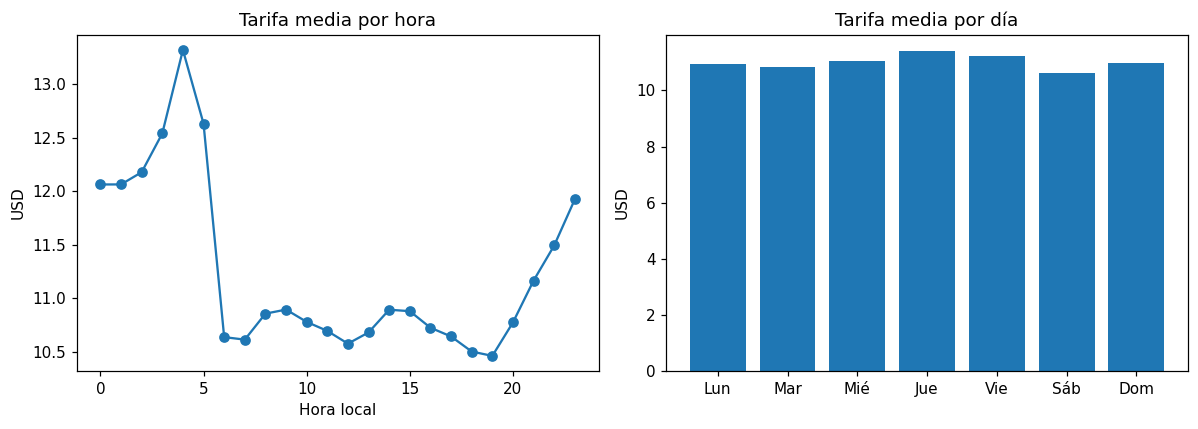

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(por_hora["hora"], por_hora["tarifa_media"], marker="o")
axes[0].set(title="Tarifa media por hora", xlabel="Hora local", ylabel="USD")
axes[1].bar(["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"], por_dia["tarifa_media"])
axes[1].set(title="Tarifa media por día", ylabel="USD")
plt.tight_layout()
plt.show()
plt.close(fig)

Observamos una tarifa media más alta alrededor de las 04:00 y valores menores cerca de las 19:00. Por día, el jueves presenta la media más alta y el sábado la más baja. Estas diferencias también pueden reflejar cambios en la distancia y duración de los viajes.

Revisamos conjuntamente la hora y el día con un mapa de calor de la tarifa media. Calculamos los promedios en Spark con todos los viajes limpios y convertimos solo los 168 grupos posibles a pandas.

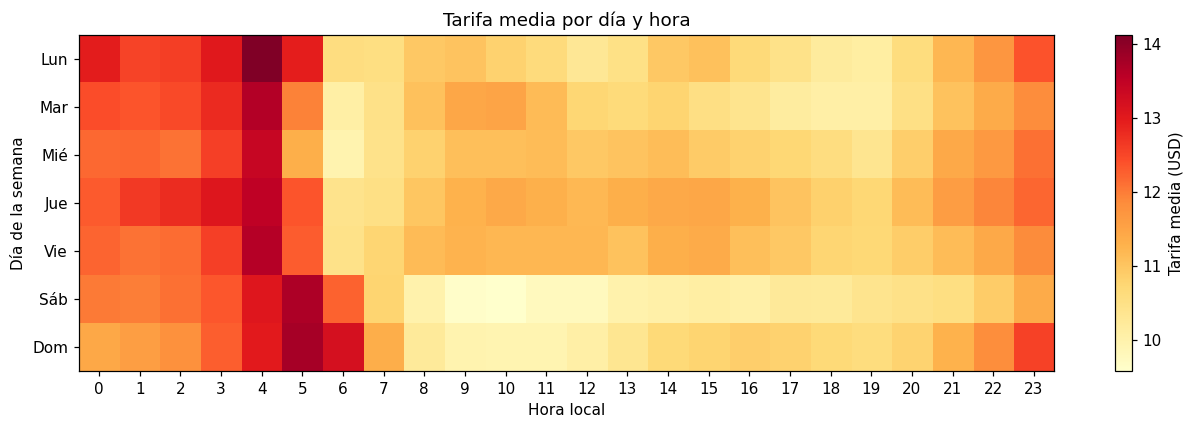

In [18]:
calendario_eda = (
    limpios.groupBy("dia_semana", "hora")
    .agg(F.avg("tarifa").alias("tarifa_media"))
    .toPandas()
)
mapa_calendario = calendario_eda.pivot(
    index="dia_semana", columns="hora", values="tarifa_media"
).reindex(index=range(1, 8), columns=range(24))

fig, ax = plt.subplots(figsize=(12, 4))
imagen = ax.imshow(mapa_calendario, aspect="auto", cmap="YlOrRd")
ax.set_xticks(range(24), range(24))
ax.set_yticks(range(7), ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"])
ax.set(title="Tarifa media por día y hora", xlabel="Hora local", ylabel="Día de la semana")
fig.colorbar(imagen, ax=ax, label="Tarifa media (USD)")
plt.tight_layout()
plt.show()
plt.close(fig)

La mayor tarifa media por combinación de día y hora se observó el **lunes a las 04:00**, con **14.13 USD**. Las diferencias motivan probar el calendario como entrada adicional, aunque también pueden reflejar cambios en distancia y duración. Comprobamos su aporte comparando la regresión base con la regresión que añade hora y día.

### **5. Particiones y Preparación del Modelo**

Separamos los viajes en entrenamiento, validación y prueba. La división aleatoria evalúa viajes similares del mismo mes, no la capacidad de predecir otros años.

In [19]:
train, val, test = limpios.randomSplit([0.70, 0.15, 0.15], seed=SEED)
particiones = {"Entrenamiento": train, "Validación": val, "Prueba": test}
conteos = {nombre: tabla.count() for nombre, tabla in particiones.items()}

Revisamos que las tres particiones tengan registros suficientes.

In [20]:
print(pd.DataFrame(conteos.items(), columns=["Conjunto", "Viajes"]).to_string(index=False))

     Conjunto  Viajes
Entrenamiento 8499684
   Validación 1821809
       Prueba 1822154


La división dejó **8,499,684 viajes** para entrenamiento, **1,821,809** para validación y **1,822,154** para prueba. Las proporciones se aproximan a 70%, 15% y 15%, con viajes suficientes para comparar los modelos.

Preparamos las variables temporales. Representamos la hora con dos componentes que conectan las 23:00 con las 00:00, y cada día con indicadores. El día lunes queda como referencia.

In [21]:
BASE = ["distancia_mi", "duracion_min"]
TEMPORALES = ["hora_seno", "hora_coseno"] + [f"dia_{dia}" for dia in range(2, 8)]
AMPLIADAS = BASE + TEMPORALES


def preparar_variables(tabla):
    """Construir las mismas entradas para entrenamiento y predicción."""
    angulo = F.col("hora") * (2 * 3.141592653589793 / 24)
    tabla = tabla.withColumn("hora_seno", F.sin(angulo)).withColumn(
        "hora_coseno", F.cos(angulo)
    )
    for dia in range(2, 8):
        tabla = tabla.withColumn(f"dia_{dia}", (F.col("dia_semana") == dia).cast("double"))
    return tabla

Convertimos las entradas en vectores y reutilizamos estas tablas durante las comparaciones. Todos los modelos reciben exactamente los mismos viajes.

In [22]:
ensamblador_base = VectorAssembler(inputCols=BASE, outputCol="features_base")
ensamblador_ampliado = VectorAssembler(inputCols=AMPLIADAS, outputCol="features")


def crear_vectores(tabla):
    return ensamblador_ampliado.transform(ensamblador_base.transform(preparar_variables(tabla)))


train_features = (
    crear_vectores(train)
    .select("tarifa", "features_base", "features")
    .persist(StorageLevel.MEMORY_AND_DISK)
)
val_features = (
    crear_vectores(val)
    .select("tarifa", "features_base", "features")
    .persist(StorageLevel.MEMORY_AND_DISK)
)

### **6. Definición de los Modelos**

Definimos una regresión base, otra con calendario y GBT con las mismas entradas ampliadas. La primera comparación revisa el aporte temporal. La segunda compara algoritmos.

In [23]:
estimadores = {
    "Lineal base": LinearRegression(
        labelCol="tarifa", featuresCol="features_base", solver="normal", regParam=0.0
    ),
    "Lineal con calendario": LinearRegression(
        labelCol="tarifa", featuresCol="features", solver="normal", regParam=0.0
    ),
    "GBT con calendario": GBTRegressor(
        labelCol="tarifa",
        featuresCol="features",
        maxIter=ITERACIONES_GBT,
        maxDepth=PROFUNDIDAD_GBT,
        stepSize=0.1,
        seed=SEED,
    ),
}

Dejamos una función para medir los tres modelos con el mismo criterio: MAE y RMSE en dólares, y R². Menor error indica una mejor predicción.

In [24]:
def evaluar(predicciones, nombre, conjunto):
    """Evaluar las predicciones con las herramientas de Spark."""
    resultado = {"Modelo": nombre, "Conjunto": conjunto}
    for salida, metrica in [("MAE_USD", "mae"), ("RMSE_USD", "rmse"), ("R2", "r2")]:
        resultado[salida] = RegressionEvaluator(
            labelCol="tarifa", predictionCol="prediction", metricName=metrica
        ).evaluate(predicciones)
    return resultado

### **7. Entrenamiento y Validación**

Entrenamos la regresión base únicamente con los viajes de entrenamiento.

In [25]:
inicio = perf_counter()
modelo_base = estimadores["Lineal base"].fit(train_features)
tiempo_base = (perf_counter() - inicio) / 60

Entrenamos la regresión ampliada para revisar si añadir hora y día mejora sus predicciones.

In [26]:
inicio = perf_counter()
modelo_calendario = estimadores["Lineal con calendario"].fit(train_features)
tiempo_calendario = (perf_counter() - inicio) / 60

Entrenamos GBT con las entradas ampliadas. Sus árboles pueden aprender relaciones más flexibles, aunque no garantizan una mejora y pueden tardar más.

In [27]:
inicio = perf_counter()
modelo_gbt = estimadores["GBT con calendario"].fit(train_features)
tiempo_gbt = (perf_counter() - inicio) / 60

Organizamos los modelos entrenados y sus tiempos para compararlos con las mismas métricas.

In [28]:
modelos = {
    "Lineal base": modelo_base,
    "Lineal con calendario": modelo_calendario,
    "GBT con calendario": modelo_gbt,
}
tiempos = {
    "Lineal base": tiempo_base,
    "Lineal con calendario": tiempo_calendario,
    "GBT con calendario": tiempo_gbt,
}

Liberamos los vectores de entrenamiento después de ajustar los tres modelos.

In [29]:
_ = train_features.unpersist()

Comparamos las predicciones de validación antes de usar la prueba. También conservamos la tarifa media de entrenamiento como referencia sencilla.

In [30]:
media_train = train.agg(F.avg("tarifa")).first()[0]
metricas_val = []
for nombre, candidato in modelos.items():
    predicciones = (
        candidato.transform(val_features)
        .select("tarifa", "prediction")
        .persist(StorageLevel.MEMORY_AND_DISK)
    )
    fila = evaluar(predicciones, nombre, "Validación")
    fila["Minutos_entrenamiento"] = tiempos[nombre]
    metricas_val.append(fila)
    _ = predicciones.unpersist()
referencia_val = val_features.select("tarifa").withColumn("prediction", F.lit(media_train))
metrica_media_val = evaluar(referencia_val, "Media", "Validación")
comparacion_val = pd.DataFrame(metricas_val).sort_values(["MAE_USD", "RMSE_USD", "Modelo"])

Revisamos los errores y el tiempo de entrenamiento en una sola tabla.

In [31]:
print(pd.DataFrame([metrica_media_val, *metricas_val]).round(3).to_string(index=False))

               Modelo   Conjunto  MAE_USD  RMSE_USD     R2  Minutos_entrenamiento
                Media Validación    5.134     7.397 -0.000                    NaN
          Lineal base Validación    0.365     0.997  0.982                  0.267
Lineal con calendario Validación    0.362     0.993  0.982                  0.096
   GBT con calendario Validación    0.738     1.350  0.967                  7.854


Las dos regresiones superaron ampliamente la referencia de la media. La versión con calendario obtuvo el menor MAE, **0.362 USD**, frente a **0.365 USD** de la base. GBT alcanzó **0.738 USD** y tardó **7.854 minutos**, así que una mayor complejidad no produjo mejora en este caso. Los tiempos incluyen el trabajo de Spark y la preparación de caché que corresponda a cada ajuste, por lo que no constituyen una comparación controlada de velocidad entre las dos regresiones.

Elegimos el modelo con menor MAE de validación. En caso de empate utilizamos RMSE y conservamos esa decisión durante la evaluación de prueba.

In [32]:
NOMBRE_MODELO = comparacion_val.iloc[0]["Modelo"]
modelo = modelos[NOMBRE_MODELO]
_ = val_features.unpersist()

Identificamos cuál fue el modelo elegido con validación.

In [33]:
print(comparacion_val.head(1).reset_index(drop=True).round(3).to_string(index=False))

               Modelo   Conjunto  MAE_USD  RMSE_USD    R2  Minutos_entrenamiento
Lineal con calendario Validación    0.362     0.993 0.982                  0.096


Seleccionamos **Lineal con calendario** por su menor error de validación. La ventaja sobre la regresión base fue pequeña, pero el criterio se fijó antes de revisar los resultados de prueba.

### **8. Evaluación del Modelo**

Preparamos los viajes de prueba sin volver a entrenar. Esta partición sirve para la evaluación final de las configuraciones ya fijadas.

In [34]:
test_features = crear_vectores(test).persist(StorageLevel.MEMORY_AND_DISK)

Evaluamos las tres alternativas en prueba. Guardamos las predicciones del modelo elegido para las siguientes secciones, sin cambiar la selección después de ver estos errores.

In [35]:
metricas_test = []
for nombre, candidato in modelos.items():
    predicciones = candidato.transform(test_features).persist(StorageLevel.MEMORY_AND_DISK)
    metricas_test.append(evaluar(predicciones, nombre, "Prueba"))
    if nombre == NOMBRE_MODELO:
        pred_test = predicciones
    else:
        _ = predicciones.unpersist()
referencia_test = test_features.select("tarifa").withColumn("prediction", F.lit(media_train))
metricas_test.append(evaluar(referencia_test, "Media", "Prueba"))
resultados_prueba = pd.DataFrame(metricas_test)
resultados_prueba["Seleccionado"] = resultados_prueba["Modelo"] == NOMBRE_MODELO

Presentamos el resultado final. MAE es el error absoluto promedio. RMSE da más peso a errores grandes. Un R² negativo indicaría un ajuste peor que usar la media del conjunto evaluado.

In [36]:
print(resultados_prueba.round(3).to_string(index=False))

               Modelo Conjunto  MAE_USD  RMSE_USD     R2  Seleccionado
          Lineal base   Prueba    0.365     0.928  0.984         False
Lineal con calendario   Prueba    0.362     0.924  0.984          True
   GBT con calendario   Prueba    0.739     1.352  0.967         False
                Media   Prueba    5.141     7.417 -0.000         False


En prueba, la regresión con calendario se equivocó en promedio aproximadamente **0.36 USD**. Su RMSE de **0.924 USD**, mayor que el MAE, indica que algunos errores fueron más grandes. El R² de **0.984** corresponde a cerca del **98.4% de la variación explicada** en este conjunto, no a un porcentaje de predicciones exactas.

Revisamos algunos aciertos y errores concretos del modelo seleccionado.

In [37]:
pred_test.select(
    "distancia_mi",
    "duracion_min",
    "hora",
    "dia_semana",
    "tarifa",
    F.round("prediction", 2).alias("tarifa_estimada"),
    F.round(F.abs(F.col("prediction") - F.col("tarifa")), 2).alias("error_usd"),
).show(5)

+------------+------------------+----+----------+------+---------------+---------+
|distancia_mi|      duracion_min|hora|dia_semana|tarifa|tarifa_estimada|error_usd|
+------------+------------------+----+----------+------+---------------+---------+
|        1.56| 5.916666666666667|   0|         4|   7.0|           7.16|     0.16|
|         3.2|18.016666666666666|   0|         4|  13.5|          14.38|     0.88|
|         5.9|              32.2|   0|         4|  24.5|          24.36|     0.14|
|        0.39|              1.25|   0|         4|   3.5|           3.32|     0.18|
|        0.39|2.6166666666666667|   0|         4|   4.0|           3.78|     0.22|
+------------+------------------+----+----------+------+---------------+---------+
only showing top 5 rows


En los cinco ejemplos mostrados, los errores absolutos estuvieron entre **0.14 y 0.88 USD**. Nos ayudan a leer predicciones concretas, pero no representan por sí solos el desempeño de todos los viajes. Para eso utilizamos las métricas completas de prueba.

### **9. Interpretación de la Comparación**

Comparamos las dos regresiones para aislar el aporte del calendario. Un cambio favorable es evidencia predictiva en este periodo, no una prueba de causalidad ni de significancia estadística.

In [38]:
comparacion_tiempo = pd.DataFrame(metricas_val).set_index("Modelo")
mae_base = comparacion_tiempo.loc["Lineal base", "MAE_USD"]
mae_calendario = comparacion_tiempo.loc["Lineal con calendario", "MAE_USD"]
aporte_tiempo = pd.DataFrame(
    {
        "MAE_base_USD": [mae_base],
        "MAE_con_calendario_USD": [mae_calendario],
        "Reduccion_MAE_USD": [mae_base - mae_calendario],
        "Reduccion_MAE_pct": [
            100 * (mae_base - mae_calendario) / mae_base if mae_base else float("nan")
        ],
    }
)
print(aporte_tiempo.round(4).to_string(index=False))

 MAE_base_USD  MAE_con_calendario_USD  Reduccion_MAE_USD  Reduccion_MAE_pct
       0.3655                  0.3618             0.0037             1.0061


Añadir el calendario redujo el MAE de validación **0.0037 USD**, aproximadamente **1.0061%**. La reducción es favorable, aunque pequeña. No podemos atribuirla por separado a la hora o al día porque incorporamos ambas variables en la misma comparación.

Agrupamos las importancias de GBT para revisar cuánto utilizó cada tipo de entrada. Estas importancias no son comparables directamente con los coeficientes de una regresión.

In [39]:
importancias = dict(zip(AMPLIADAS, modelo_gbt.featureImportances.toArray()))
importancia_grupos = pd.DataFrame(
    {
        "Variable": ["Distancia", "Duración", "Hora", "Día de la semana"],
        "Importancia_GBT": [
            importancias["distancia_mi"],
            importancias["duracion_min"],
            sum(importancias[c] for c in ["hora_seno", "hora_coseno"]),
            sum(importancias[f"dia_{dia}"] for dia in range(2, 8)),
        ],
    }
)
print(importancia_grupos.round(4).to_string(index=False))

        Variable  Importancia_GBT
       Distancia           0.6750
        Duración           0.3244
            Hora           0.0005
Día de la semana           0.0000


GBT concentró su importancia en **distancia, 67.50%**, y **duración, 32.44%**. La hora y el día aparecen como **0.0005** y **0.0000** con el redondeo mostrado. Esto describe esta configuración de GBT y no prueba que el calendario sea irrelevante para cualquier modelo.

### **10. Predicciones con Datos Nuevos**

Definimos una función para recibir distancia, duración y fecha de inicio. La función deriva el calendario igual que durante el entrenamiento.

In [40]:
def predecir_viajes(casos):
    """Estimar tarifas con el modelo seleccionado."""
    if not casos:
        raise ValueError("Agrega al menos un recorrido.")
    filas = [
        (str(nombre), float(distancia), float(duracion), str(fecha))
        for nombre, distancia, duracion, fecha in casos
    ]
    tabla = spark.createDataFrame(
        filas, "caso string, distancia_mi double, duracion_min double, inicio_texto string"
    )
    tabla = tabla.withColumn("inicio", F.to_timestamp("inicio_texto", "yyyy-MM-dd HH:mm:ss"))
    valido = (
        F.col("distancia_mi").between(0.1, 100)
        & F.col("duracion_min").between(1, 180)
        & F.col("inicio").isNotNull()
    )
    if tabla.filter(~F.coalesce(valido, F.lit(False))).count():
        raise ValueError("Revisa distancias, duraciones y fechas.")
    return modelo.transform(crear_vectores(agregar_calendario(tabla))).select(
        "caso",
        "distancia_mi",
        "duracion_min",
        "hora",
        "dia_semana",
        F.round("prediction", 2).alias("tarifa_estimada_usd"),
    )

Creamos recorridos iguales con distinto calendario para observar sus estimaciones. Son ejemplos de uso y no tienen una tarifa real con la que medir el error.

In [41]:
casos = [
    ("Lunes por la mañana", 5.0, 25.0, "2015-01-05 08:00:00"),
    ("Lunes por la noche", 5.0, 25.0, "2015-01-05 22:00:00"),
    ("Domingo por la mañana", 5.0, 25.0, "2015-01-11 08:00:00"),
]

Obtenemos las tarifas con la regresión con calendario seleccionada. Mantenemos iguales la distancia y la duración para observar los cambios asociados con la hora y el día.

In [42]:
print(predecir_viajes(casos).toPandas().to_string(index=False))

                 caso  distancia_mi  duracion_min  hora  dia_semana  tarifa_estimada_usd
  Lunes por la mañana           5.0          25.0     8           1                20.30
   Lunes por la noche           5.0          25.0    22           1                20.12
Domingo por la mañana           5.0          25.0     8           7                20.27


Para el mismo recorrido de 5 millas y 25 minutos estimamos **20.30 USD** el lunes por la mañana, **20.12 USD** el lunes por la noche y **20.27 USD** el domingo por la mañana. Las diferencias son pequeñas y consistentes con el aporte limitado del calendario. Son ejemplos creados por nosotros, no una evaluación adicional del modelo.

### **11. Exportación para Tableau**

Definimos una función para exportar cada tabla como un solo CSV. Los archivos temporales de escritura se eliminan al terminar.

In [43]:
def exportar_csv(tabla, nombre):
    """Guardar una tabla pequeña como un solo CSV."""
    SALIDAS.mkdir(parents=True, exist_ok=True)
    temporal = SALIDAS / ("tmp_" + Path(nombre).stem)
    tabla.coalesce(1).write.mode("overwrite").option("header", True).csv(str(temporal))
    shutil.move(str(next(temporal.glob("part-*.csv"))), str(SALIDAS / nombre))
    shutil.rmtree(temporal)

Resumimos todos los viajes limpios por fecha, hora, día y pago. Conservamos totales para calcular medias ponderadas correctamente en Tableau.

In [44]:
resumen = limpios.groupBy("fecha", "hora", "dia_semana", "pago").agg(
    F.count("*").alias("viajes"),
    F.sum("tarifa").alias("tarifa_total_usd"),
    F.sum("distancia_mi").alias("distancia_total_mi"),
    F.sum("duracion_min").alias("duracion_total_min"),
)

Preparamos una muestra de prueba con el modelo seleccionado. La muestra servirá para visualizar tarifas reales, estimadas y errores sin exportar millones de filas.

In [45]:
muestra_predicciones = (
    pred_test.orderBy(F.rand(SEED))
    .limit(MAX_PREDICCIONES)
    .select(
        "fecha",
        "hora",
        "dia_semana",
        "pago",
        "latitud",
        "longitud",
        *BASE,
        F.lit(NOMBRE_MODELO).alias("modelo"),
        F.round("tarifa", 2).alias("tarifa_real_usd"),
        F.round("prediction", 2).alias("tarifa_estimada_usd"),
        F.round(F.abs(F.col("prediction") - F.col("tarifa")), 2).alias("error_absoluto_usd")
    )
)

Exportamos el resumen completo para construir tendencias y comparaciones por horario.

In [46]:
exportar_csv(resumen, "resumen_viajes.csv")

Exportamos la muestra de predicciones para revisar el error y crear un mapa de recogidas.

In [47]:
exportar_csv(muestra_predicciones, "predicciones_viajes.csv")

En Tableau usamos fuentes separadas, sin unirlas directamente. Calculamos medias dividiendo la suma de cada total entre la suma de viajes. El mapa utiliza solo la muestra de prueba y las métricas completas quedan en el notebook.

### **12. Descarga de Resultados**

Preparamos la descarga de los dos CSV. Fuera de Colab, las rutas quedan disponibles en la carpeta de salida.

In [48]:
try:
    from google.colab import files
except ImportError:
    files = None

Descargamos el resumen de viajes para Tableau.

In [49]:
if files is not None:
    files.download(str(SALIDAS / "resumen_viajes.csv"))
else:
    print(SALIDAS / "resumen_viajes.csv")

/workspace/scratch/492ff72174d0/tableau_taxi/resumen_viajes.csv


Descargamos la muestra con predicciones y errores.

In [50]:
if files is not None:
    files.download(str(SALIDAS / "predicciones_viajes.csv"))
else:
    print(SALIDAS / "predicciones_viajes.csv")

/workspace/scratch/492ff72174d0/tableau_taxi/predicciones_viajes.csv


Liberamos las tablas que dejamos en memoria cuando termina el trabajo.

In [51]:
_ = pred_test.unpersist()
_ = test_features.unpersist()
_ = limpios.unpersist()

### **13. Conclusiones**

Seleccionamos la regresión lineal con calendario porque obtuvo el menor MAE de validación. En prueba alcanzó un MAE de **0.362 USD**, un RMSE de **0.924 USD** y un R² de **0.984**. El resultado fue consistente con validación y mejoró ampliamente la referencia basada en la tarifa media.

La distancia y la duración explicaron la mayor parte de la variación de la tarifa en los viajes analizados. Añadir hora y día redujo el MAE de validación aproximadamente **1.01%**, por lo que su aporte fue pequeño. Con 20 iteraciones y profundidad 3, GBT tardó **7.854 minutos** y obtuvo un MAE de prueba de **0.739 USD**. Esta configuración no mejoró la regresión lineal.

Cumplimos el flujo de carga, limpieza, preparación, entrenamiento, comparación y predicción con PySpark y MLlib. Preparamos dos CSV para complementar el análisis con el dashboard de Tableau. Los resultados se limitan a viajes estándar filtrados de enero de 2015 y no demuestran causalidad ni garantizan el mismo desempeño en otros periodos.

**[Dashboard en Tableau](https://public.tableau.com/app/profile/jorge.armando.garz.n.varela/viz/NYC-Taxi_17940032900560/NYCTaxi-ActividadyModelo)**

Complementamos el notebook con un dashboard realizado en Tableau. Utilizamos `resumen_viajes.csv` para los indicadores de viajes, tarifa media, distancia media y duración media, la tendencia por fecha y el mapa de calor por día y hora.

Con `predicciones_viajes.csv` presentamos la comparación entre tarifa real y estimada y el mapa de errores por lugar de recogida. Estas vistas utilizan una muestra de hasta 20,000 viajes de prueba. Los indicadores de actividad utilizan todos los viajes limpios.

Mostramos las fuentes por separado y calculamos las medias a partir de sus totales. El MAE que mostramos en el tablero es el de la evaluación completa de prueba, **0.362 USD**, y no uno recalculado únicamente sobre la muestra.

Los indicadores muestran **12,143,647 viajes**, una tarifa media de **11.02 USD**, una distancia media de **2.509 millas** y una duración media de **11.84 minutos**. Observamos una caída marcada de viajes hacia el final del mes y mayor actividad en varias franjas de tarde y noche. La dispersión muestra estimaciones cercanas a las tarifas reales en la mayoría de los puntos, junto con algunos errores grandes. Estas vistas describen los datos, sin establecer las causas de los patrones.

**Captura del dashboard**

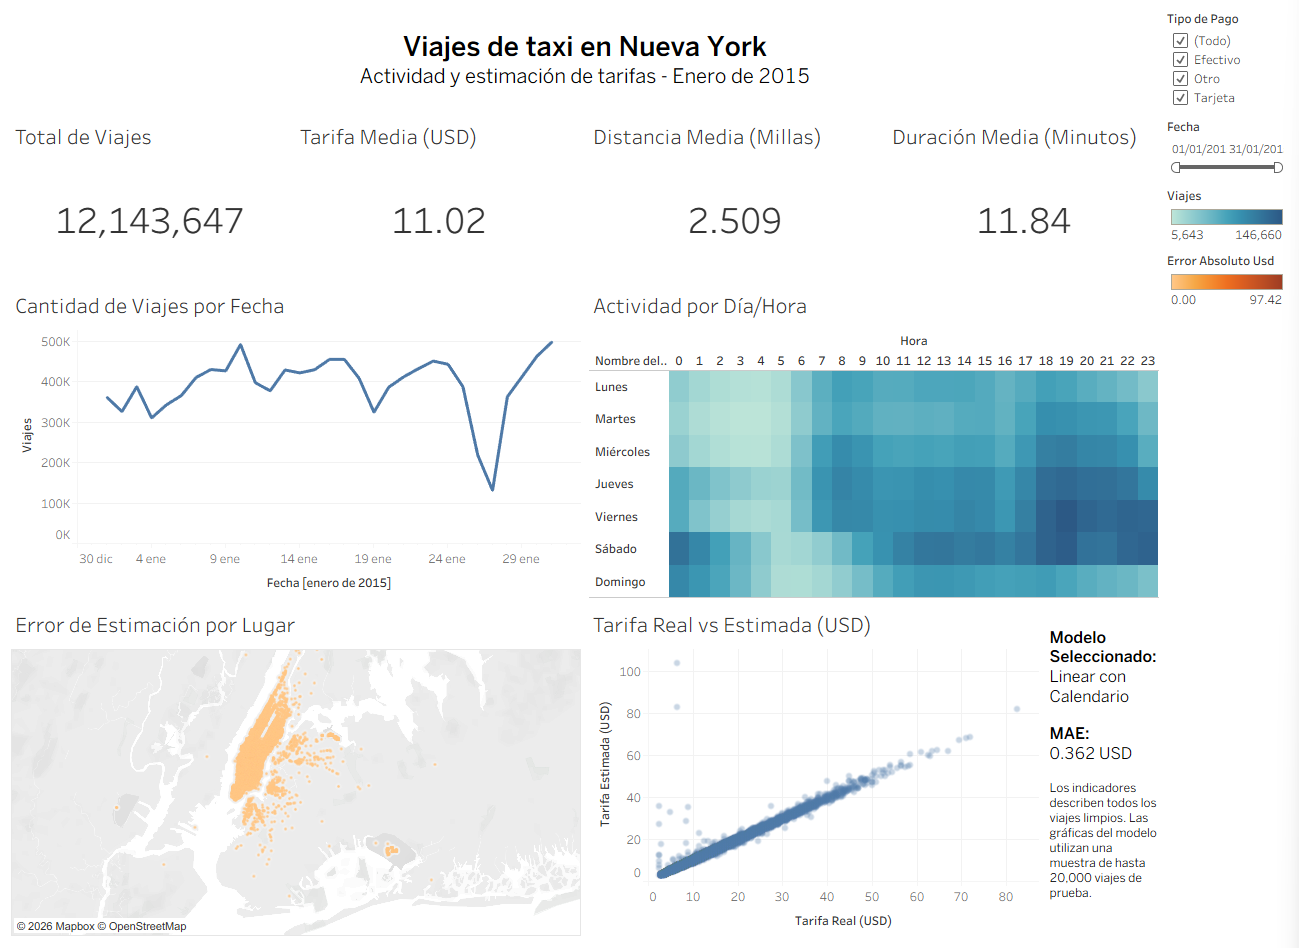

### **14. Referencias**

- [NYC Yellow Taxi en Kaggle](https://www.kaggle.com/datasets/elemento/nyc-yellow-taxi-trip-data).
- [TLC: diccionario de datos](https://www.nyc.gov/assets/tlc/downloads/pdf/data_dictionary_trip_records_yellow.pdf).
- [Apache Spark: documentación de regresión y GBT](https://spark.apache.org/docs/latest/ml-classification-regression.html).